In [2]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error



In [3]:
velocity_rpe_df = pd.read_csv("deadlift_velocity_rpe.csv")

In [4]:
velocity_rpe_df.describe()

,mean_velocity_ms
count,5000.000000
mean,0.485412
std,0.195658
min,0.080000
25%,0.350000
50%,0.460000
75%,0.600000
max,1.150000


In [5]:
velocity_rpe_df.sample(10)

,mean_velocity_ms,rpe
2089,0.59,7
3353,0.86,<5
3058,0.35,10
898,0.42,7
961,0.17,10
4685,0.15,10
906,0.36,7
912,0.26,9
1936,0.37,8
2435,0.30,8


In [6]:
%matplotlib inline

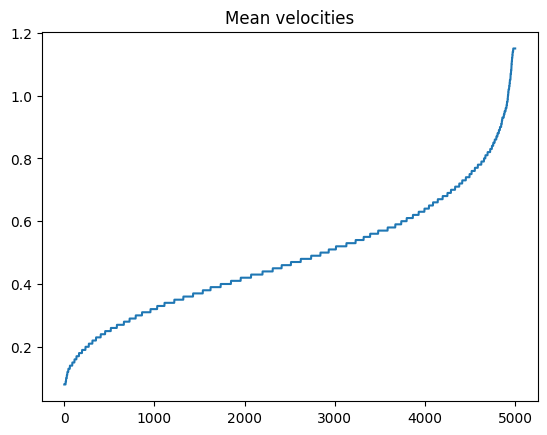

In [7]:
plt.plot(velocity_rpe_df.mean_velocity_ms.sort_values().values)
plt.title("Mean velocities")
plt.show()

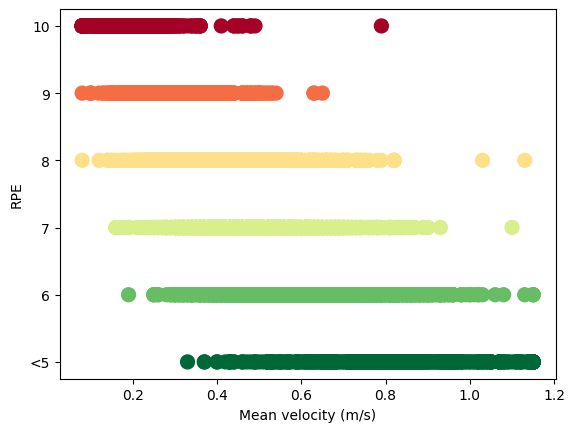

In [8]:
order = ["<5", "6", "7", "8", "9", "10"]
y = velocity_rpe_df.rpe.map({k: i for i, k in enumerate(order)})

plt.scatter(velocity_rpe_df.mean_velocity_ms, y, c=y, cmap="RdYlGn_r", s=100)
plt.yticks(range(len(order)), order)
plt.xlabel("Mean velocity (m/s)")
plt.ylabel("RPE")
plt.show()

In [9]:
#mean_velocity_rpe_decision_tree = DecisionTreeClassifier()
#mean_velocity_rpe_decision_tree.fit(velocity_rpe_df.mean_velocity_ms, y)
df = velocity_rpe_df.copy()
df["rpe_idx"] = df.rpe.map({k: i for i, k in enumerate(order)})

features = ["mean_velocity_ms"]
X, y = df[features], df["rpe_idx"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



In [10]:
model_mean_velocity_rpe = DecisionTreeClassifier(random_state=42 * 67 * 69)
model_mean_velocity_rpe.fit(X_train, y_train)


DecisionTreeClassifier(random_state=194166)

In [11]:
pred = model_mean_velocity_rpe.predict(X_test)
print(classification_report(y_test, pred, labels=range(len(order)), target_names=order, zero_division=0))
print(confusion_matrix(y_test, pred, labels=range(len(order))))

              precision    recall  f1-score   support

          <5       0.55      0.39      0.46        76
           6       0.44      0.42      0.43       214
           7       0.42      0.52      0.47       288
           8       0.43      0.40      0.41       249
           9       0.36      0.25      0.30       114
          10       0.61      0.71      0.66        59

    accuracy                           0.44      1000
   macro avg       0.47      0.45      0.45      1000
weighted avg       0.44      0.44      0.44      1000

[[ 30  38   7   1   0   0]
 [ 20  90  87  16   1   0]
 [  3  62 151  60   9   3]
 [  2  13 100  99  31   4]
 [  0   0  16  49  29  20]
 [  0   1   0   6  10  42]]


In [12]:
def visualize_predictions(velocity, actual, predicted):
    order = ["<5", "6", "7", "8", "9", "10"]
    idx = np.argsort(np.asarray(velocity))
    v = np.asarray(velocity)[idx]
    a = np.asarray(actual)[idx]
    p = np.asarray(predicted)[idx]

    plt.scatter(v, a, c=a, cmap="RdYlGn_r", s=100, alpha=0.4, label="actual")
    plt.step(v, p, where="mid", color="k", lw=2, label="model prediction")
    plt.yticks(range(len(order)), order)
    plt.xlabel("Mean velocity (m/s)")
    plt.ylabel("RPE")
    plt.legend()
    plt.show()


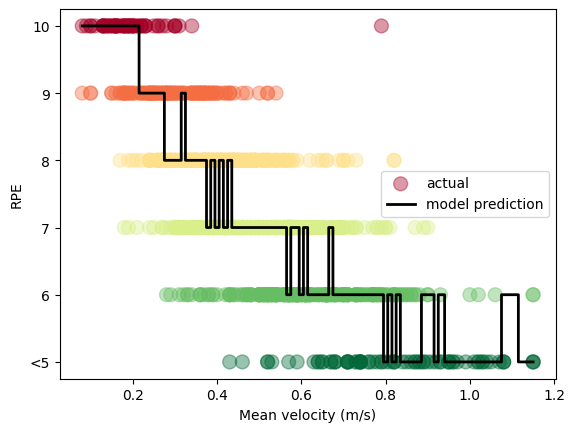

In [13]:
visualize_predictions(X_test.mean_velocity_ms, y_test, pred)

In [14]:
model_mean_velocity_rpe.predict([[0.34]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([3])

The classification model with mean velocity -> RPE works well in this example.

However, in real life, RPE doesn't just correlate to mean velocity only.

For the next step, I would try doing predictions with peak velocity aswell. Now the question would be, how is peak velocity helpful here. Usually, peak velocity correlated with average velocity.. if it's a smooth lift. However, sticking points would cause the average velocity to drop significantly, while the lifter can still carry a higher peak velocity after passing that sticking point. This is a good discussion to have, but let's rather start with visualizing first.

In [15]:
mean_peak_rpe_df = pd.read_csv("deadlift_mean_peak_rpe.csv")

In [16]:
mean_peak_rpe_df.describe()

,mean_velocity_ms,peak_velocity_ms
count,5142.000000,5142.000000
mean,0.459426,0.724331
std,0.193045,0.316982
min,-0.031990,0.067637
25%,0.320000,0.500000
50%,0.440000,0.690000
75%,0.570000,0.900000
max,1.150000,2.600000


In [17]:
mean_peak_rpe_df.sample(10)

,mean_velocity_ms,peak_velocity_ms,rpe
3485,0.62,1.69,<5
1321,0.59,0.85,6
391,0.15,0.25,9
3406,0.86,1.30,<5
3220,0.26,0.31,8
4153,0.53,0.81,6
2518,0.39,0.60,8
1026,0.35,0.77,7
2327,0.89,1.31,<5
2233,0.48,0.76,8


In [18]:
mean_peak_y = mean_peak_rpe_df.rpe.map({k: i for i, k in enumerate(order)})


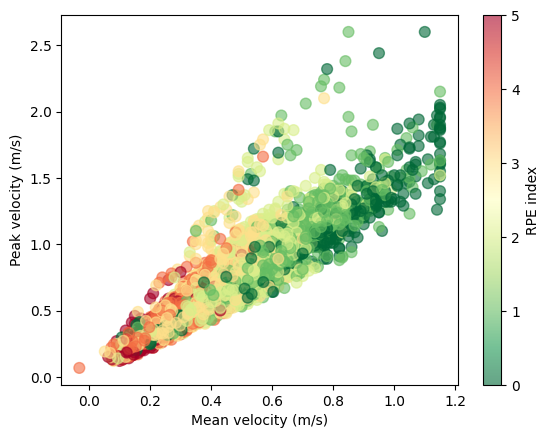

In [19]:
plt.scatter(mean_peak_rpe_df.mean_velocity_ms,
            mean_peak_rpe_df.peak_velocity_ms,
            c=mean_peak_y, cmap="RdYlGn_r", s=60, alpha=0.6)
plt.colorbar(label="RPE index")
plt.xlabel("Mean velocity (m/s)")
plt.ylabel("Peak velocity (m/s)")
plt.show()

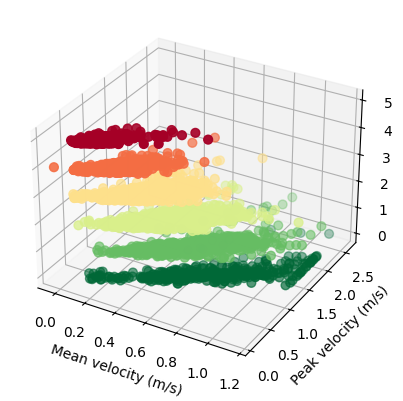

In [20]:
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.scatter(mean_peak_rpe_df.mean_velocity_ms,
           mean_peak_rpe_df.peak_velocity_ms,
           mean_peak_y, c=mean_peak_y, cmap="RdYlGn_r", s=40)
ax.set_xlabel("Mean velocity (m/s)")
ax.set_ylabel("Peak velocity (m/s)")
ax.set_zlabel("RPE")
plt.show()


In [21]:
df = mean_peak_rpe_df.copy()
df["rpe_idx"] = df.rpe.map({k: i for i, k in enumerate(order)})
df["peak_mean_ratio"] = df["mean_velocity_ms"] / df["peak_velocity_ms"]



In [22]:
df

,mean_velocity_ms,peak_velocity_ms,rpe,rpe_idx,peak_mean_ratio
0,0.630000,1.010000,7,2,0.623762
1,0.450000,0.620000,8,3,0.725806
2,0.460000,0.550000,8,3,0.836364
3,0.520000,0.830000,8,3,0.626506
4,0.150000,0.250000,9,4,0.600000
...,...,...,...,...,...
5137,0.130034,0.333431,9,4,0.389988
5138,0.123358,0.182729,10,5,0.675087
5139,0.285099,0.407794,8,3,0.699127
5140,0.051486,0.191305,8,3,0.269128


In [23]:
features = ["mean_velocity_ms", "peak_velocity_ms"]
X, y = df[features], df["rpe_idx"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [24]:
mean_peak_model = RandomForestClassifier(random_state=42 * 67 * 69)
mean_peak_model.fit(X, y)

RandomForestClassifier(random_state=194166)

In [25]:
pred = mean_peak_model.predict(X_test)
print(classification_report(y_test, pred, labels=range(len(order)), target_names=order, zero_division=0))
print(confusion_matrix(y_test, pred, labels=range(len(order))))

              precision    recall  f1-score   support

          <5       0.94      0.79      0.86        78
           6       0.75      0.70      0.72       177
           7       0.71      0.69      0.70       285
           8       0.69      0.79      0.73       268
           9       0.71      0.66      0.68       146
          10       0.75      0.75      0.75        75

    accuracy                           0.73      1029
   macro avg       0.76      0.73      0.74      1029
weighted avg       0.73      0.73      0.73      1029

[[ 62   7   6   2   1   0]
 [  1 124  36  15   0   1]
 [  3  30 198  44   9   1]
 [  0   3  34 211  14   6]
 [  0   2   5  32  96  11]
 [  0   0   0   4  15  56]]


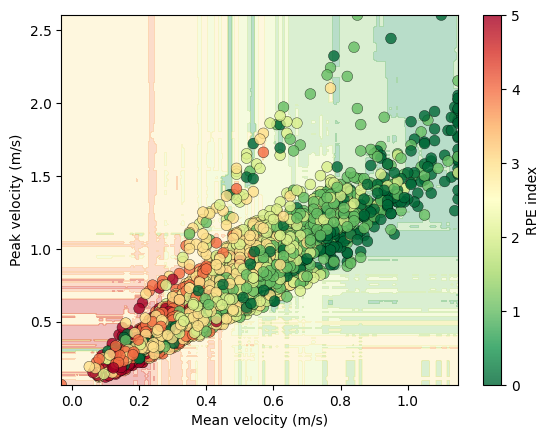

In [26]:
x = mean_peak_rpe_df.mean_velocity_ms
y = mean_peak_rpe_df.peak_velocity_ms

xx, yy = np.meshgrid(np.linspace(x.min(), x.max(), 300),
                     np.linspace(y.min(), y.max(), 300))
grid = pd.DataFrame({"mean_velocity_ms": xx.ravel(), "peak_velocity_ms": yy.ravel()})
zz = mean_peak_model.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=np.arange(-0.5, 6.5, 1), cmap="RdYlGn_r", alpha=0.3)
plt.scatter(x, y, c=mean_peak_y, cmap="RdYlGn_r", s=60, alpha=0.8, edgecolor="k", linewidth=0.3)
plt.colorbar(label="RPE index")
plt.xlabel("Mean velocity (m/s)")
plt.ylabel("Peak velocity (m/s)")
plt.show()

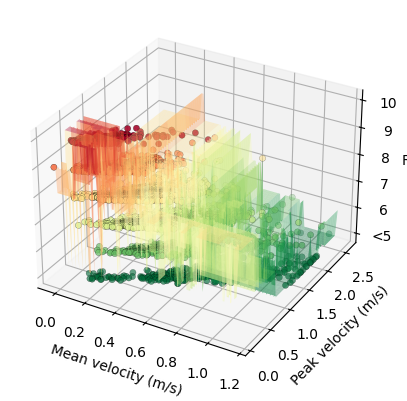

In [27]:
x = mean_peak_rpe_df.mean_velocity_ms
y = mean_peak_rpe_df.peak_velocity_ms

xx, yy = np.meshgrid(np.linspace(x.min(), x.max(), 100),
                     np.linspace(y.min(), y.max(), 100))
grid = pd.DataFrame({"mean_velocity_ms": xx.ravel(), "peak_velocity_ms": yy.ravel()})
zz = mean_peak_model.predict(grid).reshape(xx.shape)

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.plot_surface(xx, yy, zz, cmap="RdYlGn_r", alpha=0.35, linewidth=0)
ax.scatter(x, y, mean_peak_y, c=mean_peak_y, cmap="RdYlGn_r", s=20, edgecolor="k", linewidth=0.2)
ax.set_xlabel("Mean velocity (m/s)")
ax.set_ylabel("Peak velocity (m/s)")
ax.set_zlabel("RPE")
ax.set_zticks(range(6))
ax.set_zticklabels(["<5", "6", "7", "8", "9", "10"])
plt.show()

In [28]:
mean_peak_model.predict(pd.DataFrame({ "mean_velocity_ms": [0.2], "peak_velocity_ms": [0.3]}))

array([5])

The combination of mean and peak does much better, the scores were better and it seems like it understands how things can get hard :P

In [29]:
joblib.dump(mean_peak_model, "mean_peak_rpe_model.joblib")

['mean_peak_rpe_model.joblib']